# 02 · Dataset exploration and stability maps

This notebook covers Phase 3: where in parameter space each outcome occurs, and four questions
answered with decision rules fixed before the analysis.

1. Data and the held-out test set
2. Stability map
3. Outcome maps
4. Eccentricity and the Moon's orbit
5. Prograde versus retrograde orbits (rule R2)
6. Mass (rule R3)
7. The pilot gap (rule R1)
8. Survival beyond 100 years (rule R4)
9. The first second moon over 1,000 years
10. Robustness

The notebook loads saved results; the computations live in `src/` (`plot_dataset.py`,
`compare_pilot.py`, `survival_curve.py`, `long_run.py`). Run those scripts first if `data/` is
empty. Terms are defined in [`docs/glossary.md`](../docs/glossary.md); the full record is in
[`docs/report.md`](../docs/report.md).

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd

import explore
import long_run
import plot_dataset as maps
import survival_curve
from horizons import ROOT

results = json.loads((ROOT / "data" / "phase3_results.json").read_text())
pilot_check = json.loads((ROOT / "data" / "compare_pilot.json").read_text())
r4 = json.loads((ROOT / "data" / "survival_curve.json").read_text())

## 1. Data and the held-out test set

Before any exploration, 20% of the 12,000 systems were set aside as a test set, stratified so
that each outcome keeps its share (`configs/split.json`, created by `src/split.py`). Everything in
this notebook uses only the remaining training systems; the test set is reserved for the final
evaluation of the surrogate models in Phase 5. This prevents patterns noticed during exploration
from shaping the models in ways that would inflate their test scores.

In [2]:
train = explore.load_dataset("train")
split = json.loads((ROOT / "configs" / "split.json").read_text())
counts = pd.DataFrame({"train": split["train_labels"], "test": split["test_labels"]})
counts["train share"] = (counts["train"] / counts["train"].sum()).map("{:.1%}".format)
print(f"Training systems: {len(train):,}   Test systems: {split['counts']['test']:,}")
counts

Training systems: 9,600   Test systems: 2,400


,train,test,train share
ejected,3073,768,32.0%
hit_earth,2630,658,27.4%
hit_moon,137,34,1.4%
moon_lost,117,29,1.2%
survived,3643,911,37.9%


## 2. Stability map

The survival share is computed on a fixed grid: 12 logarithmic bins in semi-major axis (0.1 to 3
lunar distances) and 12 bins of 15° in inclination. Each cell holds 44 to 93 systems. The top axis
gives the semi-major axis in units of Earth's Hill radius, the distance within which Earth's
gravity dominates over the Sun's.

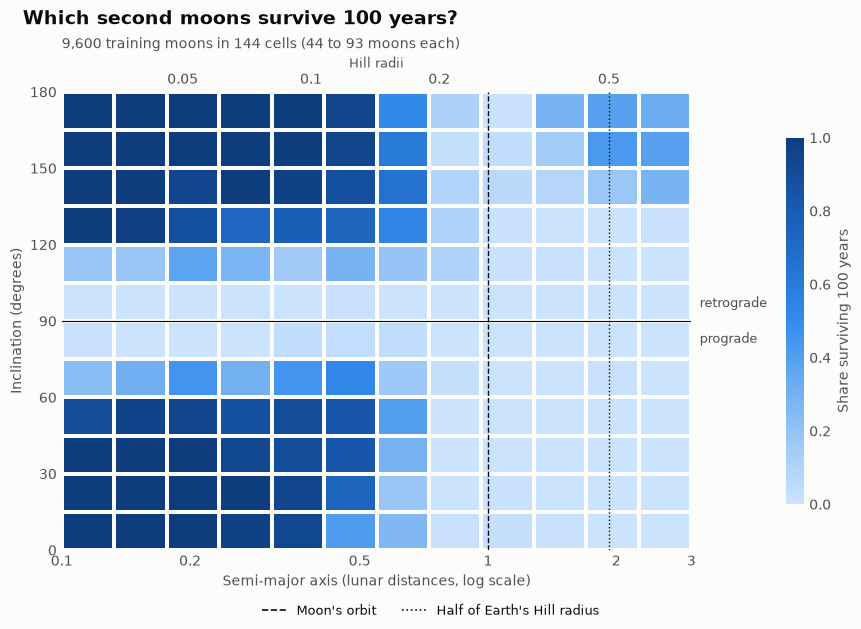

In [3]:
maps.stability_map(train);

**Result.** Survival is high inside about half the Moon's distance on low inclinations: 96.5% of
systems below 0.5 lunar distances with inclinations under 45° or over 135° survive 100 years. A
pale band around 90° crosses all distances. Beyond about 0.75 lunar distances, only near-planar
retrograde orbits keep any survival.

## 3. Outcome maps

The same grid, showing what happens to the systems that do not survive.

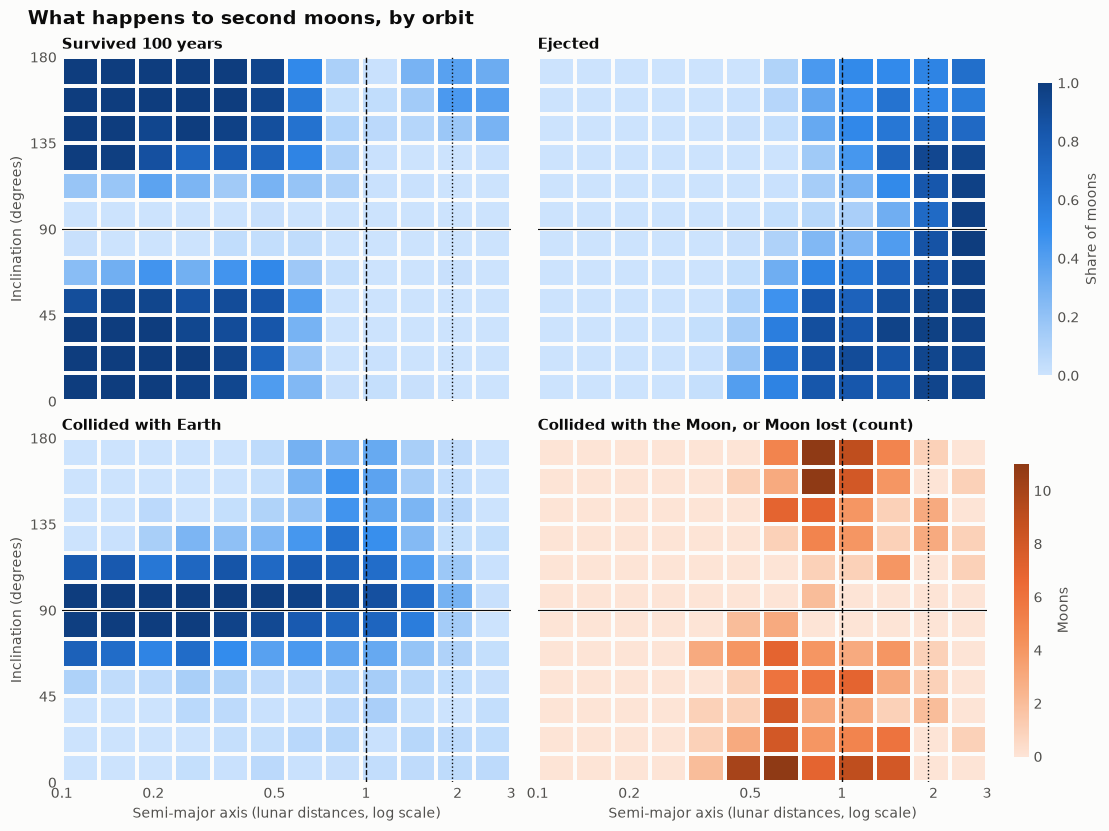

In [4]:
maps.outcome_maps(train);

**Result.** Each outcome occupies its own region:

- **Collisions with Earth** fill the near-polar band. Among close systems (below 0.5 lunar
  distances) with inclinations of 75° to 105°, 99.1% collide with Earth and 0.7% survive. This is
  consistent with Lidov–Kozai cycles: the Moon and the Sun, orbiting near the ecliptic, slowly
  convert the inclination of a strongly tilted orbit into eccentricity until its periapsis reaches
  Earth.
- **Ejections** dominate beyond the Moon's orbit.
- **The rare outcomes** (collision with the Moon, loss of the Moon) cluster between about 0.5 and
  1.5 lunar distances, where the two moons interact most strongly. This informs the Phase 4 choice
  between merging these classes and sampling that region more densely.

## 4. Eccentricity and the Moon's orbit

Survival by semi-major axis and eccentricity. The dashed curves mark orbits that just touch the
Moon's orbit; orbits between and above them cross it. The dotted curve marks periapsis at the
Roche limit; orbits closer than that were excluded when the dataset was generated.

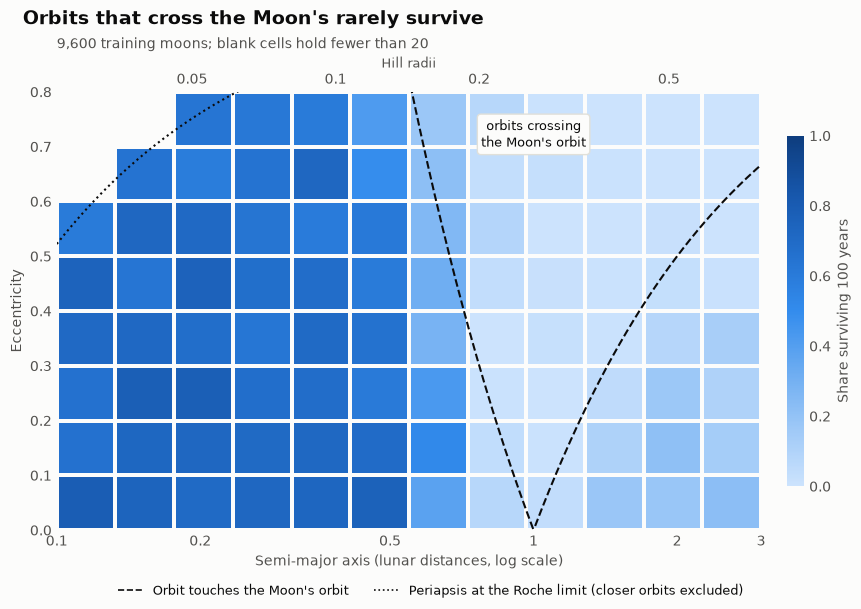

In [5]:
maps.eccentricity_map(train);

**Result.** Survival collapses once an orbit reaches the Moon's: systems whose orbits cross the
Moon's survive in 3.0% of cases, against 62.0% for systems entirely inside it. Survival also falls
steadily with eccentricity, from 47.1% below e = 0.1 to 24.0% at e = 0.7–0.8.

## 5. Prograde versus retrograde orbits (rule R2)

**Rule R2:** retrograde orbits survive farther out if the bootstrap 95% interval of the difference
between the retrograde and prograde *outer survival edges* lies above zero. The edge is the first
semi-major-axis bin beyond the bin of highest survival whose survival share falls below 10%.

Outer edge, prograde:   0.218 Hill radii
Outer edge, retrograde: 0.218 Hill radii
Difference, 95% interval: 0.000 to 0.071
Rule R2: not shown


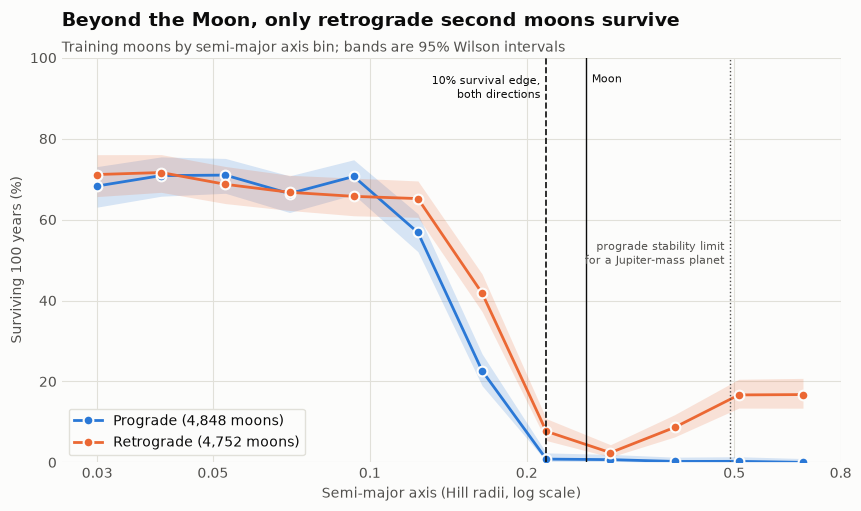

In [6]:
r2 = results["r2"]
print(f"Outer edge, prograde:   {r2['prograde_edge_hill']:.3f} Hill radii")
print(f"Outer edge, retrograde: {r2['retrograde_edge_hill']:.3f} Hill radii")
print(f"Difference, 95% interval: {r2['difference_interval'][0]:.3f} to {r2['difference_interval'][1]:.3f}")
print("Rule R2:", "retrograde farther" if r2["retrograde_farther"] else "not shown")
maps.direction_plot(train, r2);

**Result.** Rule R2 is not met: both directions fall below 10% survival in the same bin, just
inside the Moon's orbit (0.22 Hill radii). The outer limit for second moons is set by the Moon,
well inside the limit expected from the Sun alone.

Beyond the Moon's orbit, however, the two directions differ clearly (a descriptive finding, not
covered by the rule): 11.4% of retrograde systems survive against 0.3% of prograde systems,
rising to about 17% between 0.5 and 0.78 Hill radii. This agrees qualitatively with the greater
stability of retrograde satellites found in studies of planetary moons. Because all parameters
were drawn independently, the comparison is not confounded by differences in mass, eccentricity
or orientation between the two groups.

## 6. Mass (rule R3)

**Rule R3:** mass matters if the bootstrap 95% interval of the survival difference between the
heaviest and the lightest of six logarithmic mass bins excludes zero.

In [7]:
r3 = results["r3"]
table = pd.DataFrame(r3["table"])
table["mass (lunar masses)"] = table.apply(lambda r: f"{r['low']:.3f}–{r['high']:.3f}", axis=1)
table["survived"] = table.apply(
    lambda r: f"{r['survived']:.1%} ({r['survived_low']:.1%}–{r['survived_high']:.1%})", axis=1)
print(f"Heaviest minus lightest: {r3['difference']:+.1%} "
      f"(95% interval {r3['difference_interval'][0]:+.1%} to {r3['difference_interval'][1]:+.1%})")
print("Rule R3:", "mass matters" if r3["mass_matters"] else "no clear effect")
mass = results["descriptive"]["mass_outcomes"]
print(f"Moon lost: lightest bin {mass['lightest']['moon_lost']:.1%}, heaviest bin {mass['heaviest']['moon_lost']:.1%}")
table[["mass (lunar masses)", "count", "survived"]]

Heaviest minus lightest: -11.4% (95% interval -14.4% to -8.3%)
Rule R3: mass matters
Moon lost: lightest bin 0.0%, heaviest bin 7.4%


,mass (lunar masses),count,survived
0,0.001–0.003,1624,42.3% (39.9%–44.7%)
1,0.003–0.010,1630,40.0% (37.6%–42.4%)
2,0.010–0.032,1587,41.2% (38.8%–43.6%)
3,0.032–0.100,1557,37.1% (34.8%–39.6%)
4,0.100–0.316,1627,36.0% (33.7%–38.3%)
5,0.316–1.000,1575,30.9% (28.7%–33.2%)


**Result.** Rule R3 is met: survival falls from 42.3% in the lightest bin to 30.9% in the heaviest.
Part of the difference comes from the Moon itself: the heaviest second moons destabilize it in
7.4% of systems, against none for the lightest.

## 7. The pilot gap (rule R1)

The pilot (100 systems, inclinations drawn isotropically) found 18% survival; the full dataset
(inclinations uniform in degrees) finds 38%. **Rule R1:** the change of inclination sampling
explains the gap if reweighting the training systems to isotropic inclinations (weights ∝ sin i)
brings their survival share inside the pilot's 95% interval, 12% to 27%.

In [8]:
r1 = results["r1"]
print(f"Survival as sampled: {r1['unweighted_survived']:.1%}")
print(f"Reweighted to isotropic inclinations: {r1['reweighted']['survived']:.1%} "
      f"(effective sample size {r1['effective_sample_size']:,.0f})")
print("Rule R1:", "explained" if r1["explained"] else "not explained")
print()
print(f"Pilot systems re-simulated with the current code: "
      f"{pilot_check['rerun_identical']}/{pilot_check['rerun']} identical")
print(f"Expected pilot survivors from nearest training systems: {pilot_check['expected']:.1f}; "
      f"observed: {pilot_check['observed']} ({pilot_check['gap_sigma']:+.1f} standard deviations)")

Survival as sampled: 37.9%
Reweighted to isotropic inclinations: 29.7% (effective sample size 7,786)
Rule R1: not explained

Pilot systems re-simulated with the current code: 20/20 identical
Expected pilot survivors from nearest training systems: 25.4; observed: 18 (-2.1 standard deviations)


**Result.** Rule R1 is not met: reweighting lowers survival to 29.7%, just above the pilot
interval. Following the rule, other causes were investigated. Re-simulating 20 pilot systems with
the final code reproduced them exactly, ruling out a code or setting change. The survival share of
the 50 nearest training systems of each pilot system predicts 25.4 pilot survivors, so the pilot's
particular draws were less favorable than average, and the remaining gap to the observed 18 is 2.1
standard deviations of outcome noise.

| Step | Survival | Change |
|---|---:|---:|
| Training systems as sampled | 37.9% | |
| Reweighted to isotropic inclinations | 29.7% | −8.2 |
| Expected for the pilot's 100 systems | 25.4% | −4.3 |
| Observed in the pilot | 18.0% | −7.4 |

## 8. Survival beyond 100 years (rule R4)

500 randomly chosen training survivors were integrated again from the start to 1,000 years
(`configs/survivors_1000yr.json`). Their first 100 years must repeat the original runs exactly,
which serves as a reproducibility check. **Rule R4:** survival levels off if the fraction lost
between 100 and 1,000 years is less than half the fraction lost between 10 and 100 years.

All 500 present at 100 years, as in the original runs: True
Lost from 10 to 100 years:    34.7%
Lost from 100 to 1,000 years: 21.4% (95% interval 18.0% to 25.2%)
Rule R4: does not level off
Estimated share still orbiting at 1,000 years: 29.8%


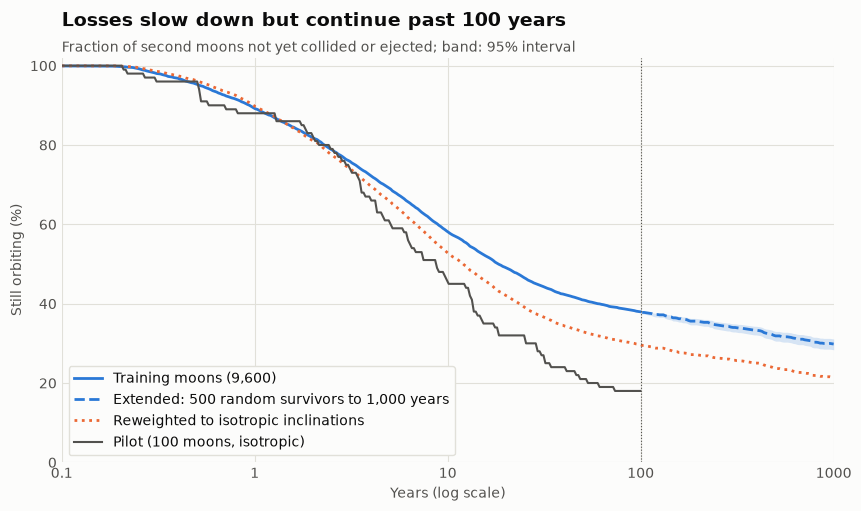

In [9]:
print(f"All 500 present at 100 years, as in the original runs: {r4['reproducible_first_100_years']}")
print(f"Lost from 10 to 100 years:    {r4['loss_10_100']:.1%}")
lo, hi = r4["loss_100_1000_interval"]
print(f"Lost from 100 to 1,000 years: {r4['loss_100_1000']:.1%} (95% interval {lo:.1%} to {hi:.1%})")
print("Rule R4:", "levels off" if r4["levels_off"] else "does not level off")
print(f"Estimated share still orbiting at 1,000 years: {r4['alive_1000']:.1%}")
ext, _ = survival_curve.load_extended()
survival_curve.plot(train, ext, r4);

**Result.** Rule R4 is not met: 21.4% of 100-year survivors are lost by 1,000 years, slower than
the 34.7% lost between 10 and 100 years but more than half of it. An estimated 29.8% of training
systems would still be orbiting after 1,000 years. The label `survived` (100 years) is therefore
a lower bound on lifetime, and part of the systems labeled `survived` would fail on longer
timescales.

## 9. The first second moon over 1,000 years

The system from notebook 01 (0.1 lunar masses on a circular, planar orbit at 0.4 lunar distances)
was integrated for 1,000 years with outputs every 10 days (`src/long_run.py`).

  Years    0-  10: second moon e mean 0.0304, max 0.0540
  Years   90- 100: second moon e mean 0.0351, max 0.0542
  Years  490- 500: second moon e mean 0.0231, max 0.0476
  Years  990-1000: second moon e mean 0.0245, max 0.0477
  Largest e over 1,000 years: 0.0547 at year 937
  Semi-major axis range: 153,580 to 154,973 km
  10-year mean eccentricity between 0.013 and 0.039
  First half average 0.0242, second half 0.0242
  Strongest cycle: 17.24 years; strongest slow cycle (5-500 years): 17.2 years


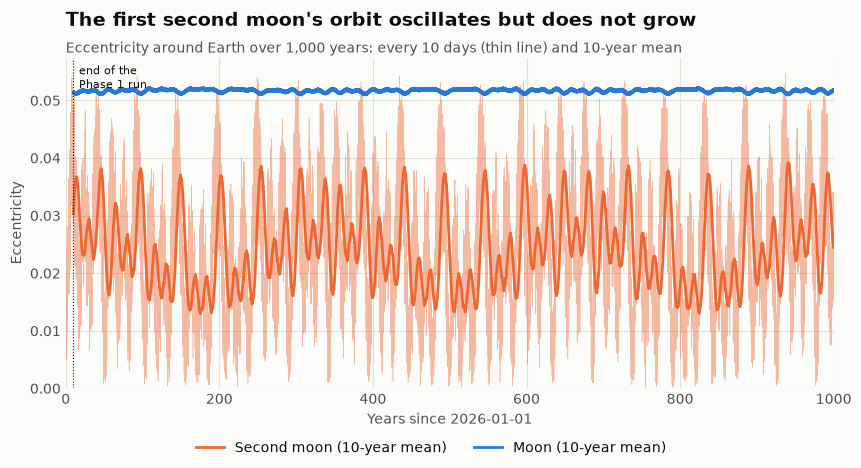

In [10]:
long_term = long_run.load()
long_run.summarize(long_term)
long_run.plot(long_term);

**Result.** The system survives 1,000 years. The eccentricity oscillates with a dominant period of
about 17 years; its 10-year mean stays between 0.013 and 0.039 and averages 0.0242 in both halves
of the run. The growth of the distance range seen over the first 10 years in notebook 01 was the
rising part of a bounded oscillation.

## 10. Robustness

Each map was rebuilt separately from systems with even and odd ids, and the two halves compared
cell by cell (count-weighted correlation).

In [11]:
for name, r in results["robustness"].items():
    print(f"{name}: correlation {r['correlation']:.3f} over {r['cells']} cells")

distance_x_tilt: correlation 0.991 over 141 cells
distance_x_eccentricity: correlation 0.977 over 93 cells


**Result.** The halves agree closely (0.991 and 0.977), so the structures in the maps are not
sampling noise.

## Summary

- Three regions dominate the outcomes: close, low-inclination orbits survive; near-polar orbits
  are driven into Earth; orbits that reach the Moon's are ejected or collide.
- The Moon, not the Sun, sets the outer limit for prograde second moons; only retrograde moons
  survive beyond the Moon's orbit.
- Heavier second moons survive less often, partly because they destabilize the Moon.
- The difference between the pilot and the full dataset is accounted for by the sampling design,
  the pilot's small size and outcome noise.
- Losses continue beyond 100 years at a slower rate.

## Carried into Phase 4

- The two rare outcomes (1.4% and 1.2%) are concentrated near the Moon's orbit: merge them, or
  sample that region more densely.
- Geometric quantities such as periapsis, apoapsis relative to the Moon's orbit, and inclination
  relative to 90° separate the outcome regions and are candidate features.
- The test set remains untouched until the final evaluation.